# What Drives Emergency Department Wait Times Across U.S. Hospitals?
**BA780 Final Project · Cohort A · Team 4**

**Team members:** Hassan Imran Malik (Project Manager) · Aashna Pathi · Michael · Weiran Wang

## Executive Summary
**Objective.** Our goal was to find out what drives emergency department (ED) wait times across the United States. We combined three public datasets on 4,080 U.S. hospitals and analyzed them to gather as many insights as possible about the hospitals, their patients and the states they are in. Our motivation was to see what drives these wait times and what can be done to reduce them.

**Method.** We cleaned and joined CMS hospital data and Census state data into one table, ranked the factors linked to longer waits, compared hospitals of the same ED size, compared the fastest and slowest of the busiest EDs, measured what long waits cost patients, and compared states using maps, correlations and a linear regression.

**Key findings**

1. **The hospitals themselves:** ED volume is the strongest driver of wait times (39% of the differences) while star ratings barely matter (under 1%). Waits rise from 120 minutes at low-volume EDs to 192.5 at very-high-volume EDs, and the slowest busy EDs keep psychiatric patients far longer than the fastest (368 vs. 222 minutes).

2. **The patients:** the share of patients who leave before being seen rises from 0.7% at EDs under two hours to 3.9% at EDs over four hours, and psychiatric and transferred patients wait the longest.

3. **The states:** richer states do not have shorter waits. Massachusetts (211.5 minutes) is slow despite a strong economy, while Minnesota (126 minutes) is fast because most of its hospitals are small rural ones.

**Recommendations**

- Add capacity at the slowest very-high-volume EDs: about 48 minutes saved per visit and at least 116,000 patients a year kept from leaving unseen.

- Move admitted, psychiatric and transferred patients out of the ED faster.

- Compare EDs with peers of the same size instead of relying on star ratings.

## Introduction and Motivation
Emergency department (ED) wait times vary widely across the United States: at some hospitals the typical visit lasts under two hours, at others more than five. Long waits are linked to worse patient outcomes and to patients leaving before a doctor sees them. Yet it is not obvious *why* some EDs are slow. Is it the hospital's size, its owner, its quality, its patients, or the economy of the area around it?

This analysis answers that question with data on more than 4,000 hospitals across all 50 states. It is written for **hospital operations leaders** deciding where to add staff and capacity and for **state health departments** deciding where to direct ED funding. Our aim is to find which factors make some EDs slower than others and to turn these findings into practical recommendations.

**Main outcome:** `OP_18b`, the median time patients spend in the ED from arrival to departure excluding psychiatric and transfer patients. Lower is better.

**Data:** three public U.S. government datasets, stored in our [GitHub repository](https://github.com/Hassan02052002/ba780-er-wait-times) and loaded directly from there:
- [CMS Timely and Effective Care – Hospital](https://data.cms.gov/provider-data/dataset/yv7e-xc69): ED wait times (Oct 2024 – Sep 2025), ED volume and patients leaving before being seen (2024)
- [CMS Hospital General Information](https://data.cms.gov/provider-data/dataset/xubh-q36u): hospital type, ownership and star rating
- [U.S. Census ACS 2024 1-Year, Table DP03](https://data.census.gov/table/ACSDP1Y2024.DP03?g=010XX00US$0400000): state income, employment, insurance and commuting

## Notebook Structure

0. **Setup:** libraries and the three datasets, loaded from GitHub

1. **Team Assignment Summary:** condensed cleaning of the three datasets, four charts from the team assignment, and the merge into one table, `final_data` (Charts 1–4)

2. **What Drives ED Wait Times?** (Charts 5–15), in four parts that build on each other:
   - **Part 1: The Big Picture and the Hospital** (Hassan Imran Malik): which factors matter most, ED volume, Critical Access hospitals and what separates fast and slow busy EDs (Charts 5–8)
   - **Part 2: The Patients** (Michael): who leaves before being seen, and how long psychiatric and transferred patients wait (Charts 9–10)
   - **Part 3: Owners and Rural States** (Weiran Wang): ownership, star ratings, the fastest busy EDs and rural states (Charts 11–12)
   - **Part 4: States and the Economy** (Aashna Pathi): two U.S. maps, an income regression and a Massachusetts vs. Minnesota case study (Charts 13–15)

3. **Recommendations:** five actions with estimated impact
4. **Conclusion**
5. **Challenges**
6. **References**
7. **Generative AI Disclosure**

---
# 0. Setup
Loads the libraries and all three datasets from our GitHub repository, so the notebook runs in Colab or Jupyter with **Restart & Run All**. Plotly is used only for the two U.S. maps and scikit-learn only for the regression models.

In [76]:
# Plotly is preinstalled in Colab; this line installs it (and nbformat, for interactive charts) in other environments
%pip install -q plotly nbformat

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px                          # U.S. maps (Charts 13 and 14, Part 4)
from sklearn.linear_model import LinearRegression    # for state-level regression (Part 4)

np.random.seed(10) # in honor of Messi

DATA_URL = "https://raw.githubusercontent.com/Hassan02052002/ba780-er-wait-times/main/data/"
care_raw = pd.read_csv(DATA_URL + "timely_effective_care_hospital.csv", dtype={"Facility ID": str, "ZIP Code": str})
hgi = pd.read_csv(DATA_URL + "hospital_general_information.csv", dtype={"Facility ID": str, "ZIP Code": str})
acs = pd.read_csv(DATA_URL + "acs_dp03_2024_states.csv", dtype={"GEO_ID": str})

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("CMS Timely and Effective Care:", care_raw.shape)
print("CMS Hospital General Information:", hgi.shape)
print("Census ACS DP03 (states):", acs.shape)

CMS Timely and Effective Care: (138084, 16)
CMS Hospital General Information: (5419, 38)
Census ACS DP03 (states): (52, 25)


---
# 1. Team Assignment Summary
This section repeats the cleaning from our team assignment in condensed form, with four of its charts. Full cleaning logs and exploratory answers are in the team assignment notebook.

### 1.1 ED Wait Times and Crowding (CMS Timely and Effective Care)
We keep the four wait-time measures (`OP_18a`–`OP_18d`), turn the text "Not Available" into missing values, reshape to one row per hospital, blank out impossible medians over 24 hours, and drop hospitals without the main outcome (`OP_18b`). We do the same for ED volume (`EDV`) and the share of patients who left before being seen (`OP_22`).

In [78]:
wait_measures = ["OP_18a", "OP_18b", "OP_18c", "OP_18d"]
waits_long = care_raw[care_raw["Measure ID"].isin(wait_measures)].copy()
waits_long["Score"] = waits_long["Score"].replace("Not Available", np.nan)
waits_long["Score"] = pd.to_numeric(waits_long["Score"])

# One row per hospital
waits = waits_long.pivot(index=["Facility ID", "Facility Name", "State"], columns="Measure ID", values="Score")
waits = waits.reset_index()
waits.columns = ["facility_id", "facility_name", "state", "op_18a_min", "op_18b_min", "op_18c_min", "op_18d_min"]

# A hospital-wide median above 24 hours is not realistic
minute_columns = ["op_18a_min", "op_18b_min", "op_18c_min", "op_18d_min"]
for column in minute_columns:
    waits.loc[waits[column] > 24 * 60, column] = np.nan
waits_clean = waits.dropna(subset=["op_18b_min"]).reset_index(drop=True)

# ED volume (EDV) and % of patients who left before being seen (OP_22), one row per hospital
crowding_long = care_raw[care_raw["Measure ID"].isin(["EDV", "OP_22"])].copy()
crowding_long["Score"] = crowding_long["Score"].replace("Not Available", np.nan)
crowding = crowding_long.pivot(index="Facility ID", columns="Measure ID", values="Score")
crowding = crowding.reset_index()
crowding.columns = ["facility_id", "edv_level", "op_22_left_pct"]
crowding["op_22_left_pct"] = pd.to_numeric(crowding["op_22_left_pct"])

print("Hospitals with the main outcome:", len(waits_clean))
print("Hospitals in the crowding table:", len(crowding))

Hospitals with the main outcome: 4081
Hospitals in the crowding table: 4658


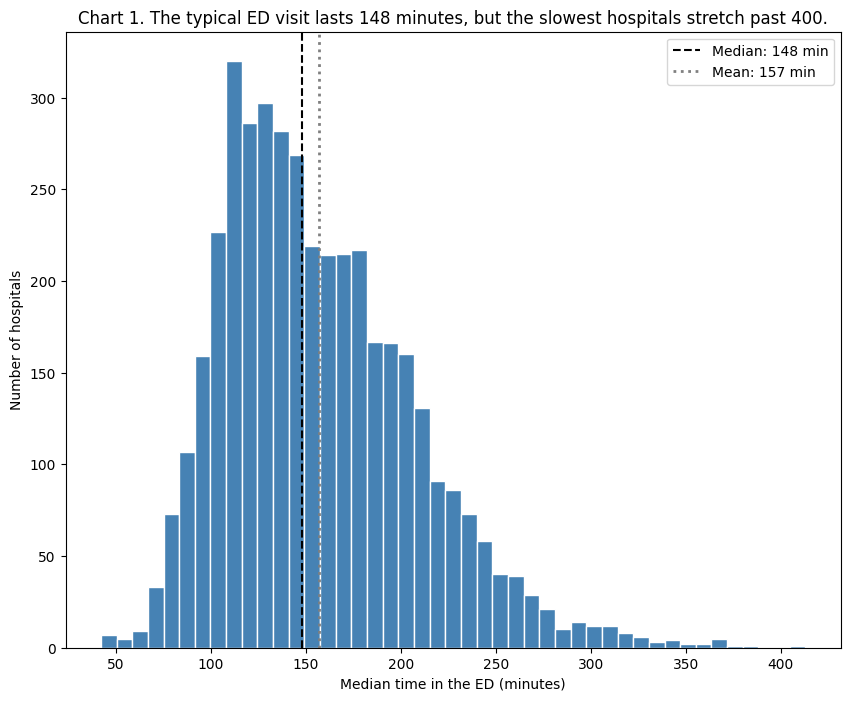

In [79]:
wait_minutes = waits_clean["op_18b_min"]

# Chart 1: distribution of the main outcome
plt.figure(figsize=(10, 8))
plt.hist(wait_minutes, bins=45, color="steelblue", edgecolor="white")
plt.axvline(wait_minutes.median(), color="black", linestyle="--", label=f"Median: {wait_minutes.median():.0f} min")
plt.axvline(wait_minutes.mean(), color="gray", linestyle=":", linewidth=2, label=f"Mean: {wait_minutes.mean():.0f} min")
plt.title("Chart 1. The typical ED visit lasts 148 minutes, but the slowest hospitals stretch past 400.")
plt.xlabel("Median time in the ED (minutes)")
plt.ylabel("Number of hospitals")
plt.legend()
plt.show()

**Insight:** the typical hospital's median ED visit is **148 minutes**, with the middle half of hospitals between 119 and 188 minutes and a long tail of slow hospitals reaching 413 minutes.

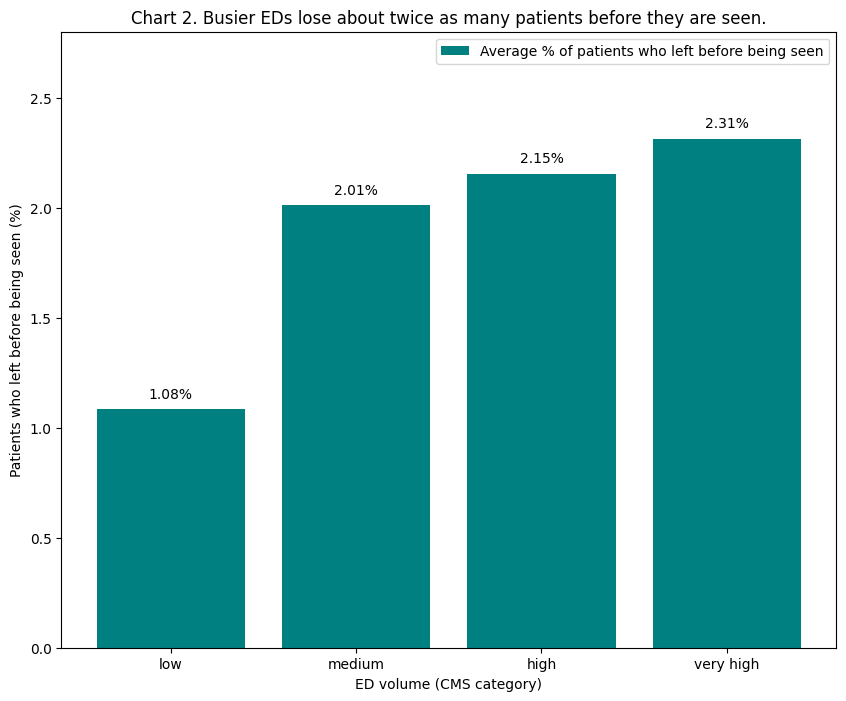

In [80]:
volume_order = ["low", "medium", "high", "very high"]
left_by_volume = crowding.groupby("edv_level")["op_22_left_pct"].mean()
left_by_volume = left_by_volume.loc[volume_order]

# Chart 2: who left before being seen, by ED volume
plt.figure(figsize=(10, 8))
plt.bar(left_by_volume.index, left_by_volume, color="teal", label="Average % of patients who left before being seen")

for level, value in zip(left_by_volume.index, left_by_volume):
    plt.text(level, value + 0.05, f"{value:.2f}%", ha="center")

plt.title("Chart 2. Busier EDs lose about twice as many patients before they are seen.")
plt.xlabel("ED volume (CMS category)")
plt.ylabel("Patients who left before being seen (%)")
plt.ylim(0, 2.8)
plt.legend()
plt.show()

:**Insight:** busier EDs lose about **twice as many patients** before they are seen, the first sign that ED volume matters. Part 2 of Section 2 tests this in depth.

### 1.2 Hospital Characteristics (CMS Hospital General Information)
We replace hidden "Not Available" text with missing values, fix data types, create True/False flags, group the 12 ownership labels into 5 groups and rename the columns to snake_case.

In [81]:
hgi.replace('Not Available', np.nan, inplace=True)

# Fix data types
hgi['Hospital overall rating'] = pd.to_numeric(hgi['Hospital overall rating']).astype('Int64')
numeric_cols = [col for col in hgi.columns if 'count' in col.lower()]
numeric_cols.remove('County/Parish')
hgi[numeric_cols] = hgi[numeric_cols].apply(pd.to_numeric)

# True/False flags
hgi['Has_ER'] = hgi['Emergency Services'].map({'Yes': True, 'No': False})
hgi['Birthing Friendly'] = hgi['Meets criteria for birthing friendly designation'].replace(np.nan, 'N').map({'Y': True, 'N': False})

# Drop footnotes and the phone number
footnote_cols = [col for col in hgi.columns if 'footnote' in col.lower()]
hgi_cleaned = hgi.drop(columns=footnote_cols + ['Telephone Number'])

# Simplify the 12 ownership labels into 5 groups (used claude here!)
owner_dict = {'Voluntary non-profit - Private': 'Non profit', 'Voluntary non-profit - Other': 'Non profit',
              'Voluntary non-profit - Church': 'Non profit', 'Proprietary': 'For profit', 'Physician': 'For profit',
              'Government - State': 'Government', 'Government - Local': 'Government',
              'Government - Hospital District or Authority': 'Government', 'Veterans Health Administration': 'Federal',
              'Department of Defense': 'Federal', 'Government - Federal': 'Federal', 'Tribal': 'Tribal'}
hgi_cleaned['Ownership Group'] = hgi_cleaned['Hospital Ownership'].map(owner_dict)

hgi_cleaned['is_territory'] = hgi_cleaned['State'].isin(['PR', 'GU', 'VI', 'AS', 'MP'])
hgi_cleaned['is_critical_access'] = hgi_cleaned['Hospital Type'] == 'Critical Access Hospitals'
hgi_cleaned['Rating_missing'] = hgi_cleaned['Hospital overall rating'].isnull()

# Snake_case column names
hgi_cleaned.columns = hgi_cleaned.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('/', '_')
print(hgi_cleaned.shape)

(5419, 37)


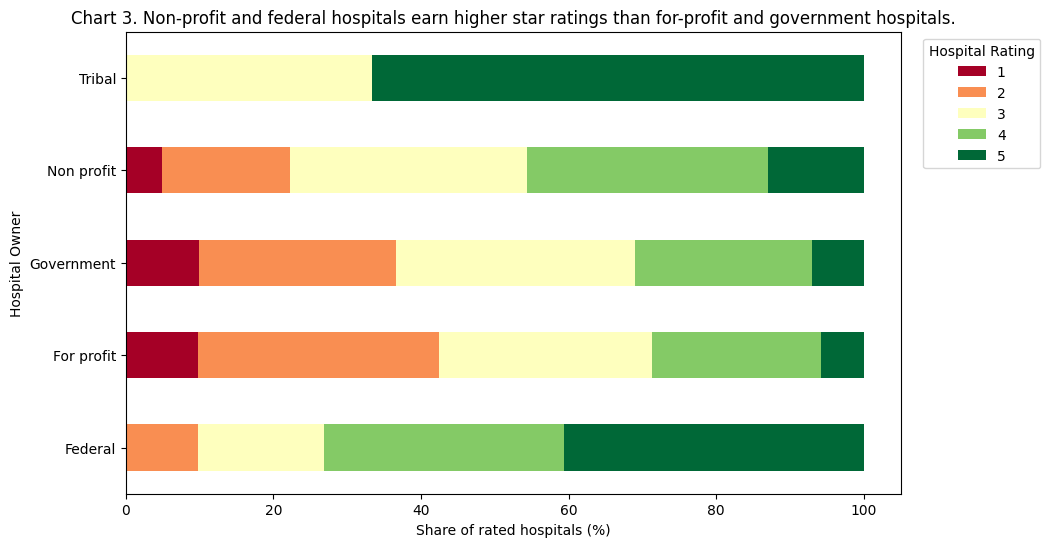

In [82]:
hgi_rating = hgi_cleaned[hgi_cleaned['hospital_overall_rating'].notna()]
table_rating_by_group = pd.crosstab(hgi_rating['ownership_group'], hgi_rating['hospital_overall_rating'], normalize='index') * 100

# Chart 3: share of each star rating within each ownership group
ax = table_rating_by_group.plot(kind='barh', stacked=True, colormap='RdYlGn', figsize=(10, 6))
ax.set_title('Chart 3. Non-profit and federal hospitals earn higher star ratings than for-profit and government hospitals.')
ax.set_xlabel('Share of rated hospitals (%)')
ax.set_ylabel('Hospital Owner')
ax.legend(title='Hospital Rating', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

**Insight:** star ratings differ by owner. Section 2 tests whether ownership and ratings also relate to ED wait times.

### 1.3 State Economic Conditions (Census ACS DP03)
We rename the Census codes to readable names (used claude to write the census names using dataset info and ofc state letters).

In [83]:
census_names = {
    "GEO_ID": "geo_id", "NAME": "state_name", "DP03_0002PE": "labor_force_pct", "DP03_0009PE": "unemployment_pct",
    "DP03_0021PE": "public_transit_pct", "DP03_0024PE": "work_from_home_pct", "DP03_0025E": "commute_min",
    "DP03_0042PE": "edu_health_jobs_pct", "DP03_0062E": "median_hh_income", "DP03_0062M": "median_hh_income_moe",
    "DP03_0063E": "mean_hh_income", "DP03_0088E": "per_capita_income", "DP03_0092E": "median_worker_earnings",
    "DP03_0066PE": "social_security_pct", "DP03_0074PE": "snap_pct", "DP03_0096PE": "insured_pct",
    "DP03_0097PE": "private_insurance_pct", "DP03_0098PE": "public_insurance_pct", "DP03_0099PE": "uninsured_pct",
    "DP03_0099PM": "uninsured_pct_moe", "DP03_0101PE": "uninsured_kids_pct", "DP03_0119PE": "family_poverty_pct",
    "DP03_0128PE": "poverty_pct", "DP03_0129PE": "child_poverty_pct", "DP03_0135PE": "senior_poverty_pct",
}
acs = acs.rename(columns=census_names)

State_Letters = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR", "California": "CA", "Colorado": "CO",
    "Connecticut": "CT", "Delaware": "DE", "District of Columbia": "DC", "Florida": "FL", "Georgia": "GA",
    "Hawaii": "HI", "Idaho": "ID", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
    "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA",
    "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS", "Missouri": "MO", "Montana": "MT",
    "Nebraska": "NE", "Nevada": "NV", "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM",
    "New York": "NY", "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
    "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC", "South Dakota": "SD",
    "Tennessee": "TN", "Texas": "TX", "Utah": "UT", "Vermont": "VT", "Virginia": "VA", "Washington": "WA",
    "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY", "Puerto Rico": "PR"
}
acs["state"] = acs["state_name"].map(State_Letters)
acs["is_territory"] = acs["state"] == "PR"

final_acs_dataset = acs.drop(columns="geo_id")
United_States_values = {"median_hh_income": 81604, "uninsured_pct": 8.2} # U.S. national values from the Census ACS 2024 DP03 table (not in our state file, so entered by hand)
print(final_acs_dataset.shape)

# original code here was way too long with all states in rows in the team assignment, used claude to condense it down so it feels simpler and makes the notebook easier to navigate!

(52, 26)


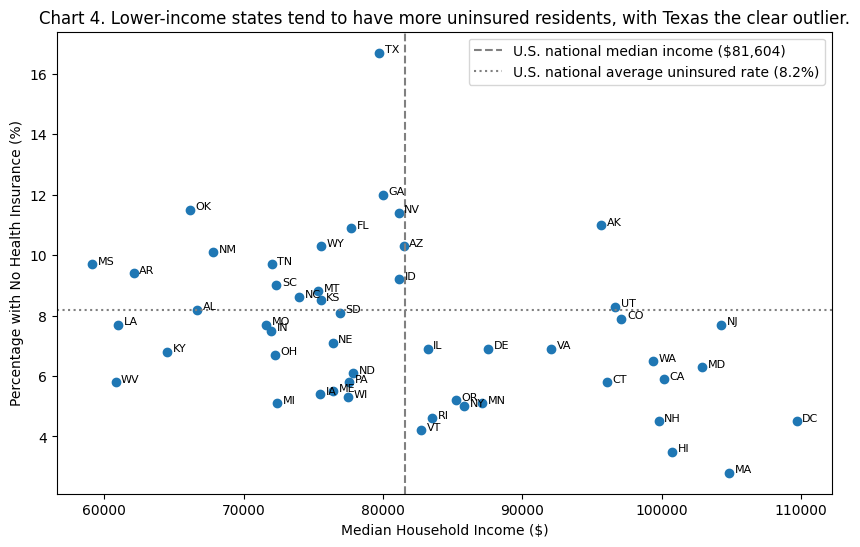

In [84]:
chart_data = final_acs_dataset[final_acs_dataset["state"] != "PR"]

# Chart 4: state income vs. uninsured rate
plt.figure(figsize=(10, 6))
plt.scatter(chart_data["median_hh_income"], chart_data["uninsured_pct"])
for i in chart_data.index:
    plt.text(chart_data.loc[i, "median_hh_income"] + 400, chart_data.loc[i, "uninsured_pct"], chart_data.loc[i, "state"], fontsize=8)
plt.axvline(United_States_values["median_hh_income"], color="gray", linestyle="--", label="U.S. national median income ($81,604)")
plt.axhline(United_States_values["uninsured_pct"], color="gray", linestyle=":", label="U.S. national average uninsured rate (8.2%)")
plt.title("Chart 4. Lower-income states tend to have more uninsured residents, with Texas the clear outlier.")
plt.xlabel("Median Household Income ($)")
plt.ylabel("Percentage with No Health Insurance (%)")
plt.legend()
plt.show()

**Insight:** lower-income states tend to have more uninsured residents, with Texas the clear outlier at 16.7%.

### 1.4 Combined Dataset
The wait-time table is the base. Hospital characteristics and state economics are added with inner joins, and the crowding measures with a left join so that no hospital is lost.

In [85]:
hospital_info = hgi_cleaned.drop(columns=["facility_name", "state", "is_territory"])
final_data = pd.merge(waits_clean, hospital_info, on="facility_id", how="inner")
final_data = pd.merge(final_data, final_acs_dataset, on="state", how="inner")  #. used inner join to get rid of any rows for which we are missing data in all 3 datasets
final_data = pd.merge(final_data, crowding, on="facility_id", how="left") # combine crowding data (edv_level : volume) with all hospitals that are present in final_data (left join)

print(final_data.shape)
final_data.head(3)

(4080, 67)


,facility_id,facility_name,state,op_18a_min,op_18b_min,op_18c_min,op_18d_min,address,city_town,zip_code,county_parish,hospital_type,hospital_ownership,emergency_services,meets_criteria_for_birthing_friendly_designation,hospital_overall_rating,mort_group_measure_count,count_of_facility_mort_measures,count_of_mort_measures_better,count_of_mort_measures_no_different,count_of_mort_measures_worse,safety_group_measure_count,count_of_facility_safety_measures,count_of_safety_measures_better,count_of_safety_measures_no_different,...,unemployment_pct,public_transit_pct,work_from_home_pct,commute_min,edu_health_jobs_pct,median_hh_income,median_hh_income_moe,mean_hh_income,per_capita_income,median_worker_earnings,social_security_pct,snap_pct,insured_pct,private_insurance_pct,public_insurance_pct,uninsured_pct,uninsured_pct_moe,uninsured_kids_pct,family_poverty_pct,poverty_pct,child_poverty_pct,senior_poverty_pct,is_territory,edv_level,op_22_left_pct
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,AL,214.00,212.00,NaN,NaN,1108 ROSS CLARK CIRCLE,DOTHAN,36301,HOUSTON,Acute Care Hospitals,Government - Hospital District or Authority,Yes,Y,4,8.00,8.00,0.00,8.00,0.00,8.00,7.00,3.00,4.00,...,4.20,0.40,8.30,26.00,22.90,66659,780,90741,36940,41871,34.80,13.10,91.80,67.50,37.90,8.20,0.30,4.30,10.90,15.20,20.20,13.00,False,very high,3.00
1,010005,MARSHALL MEDICAL CENTERS,AL,146.00,143.00,242.00,332.00,2505 U S HIGHWAY 431 NORTH,BOAZ,35957,MARSHALL,Acute Care Hospitals,Government - Hospital District or Authority,Yes,Y,3,8.00,6.00,0.00,5.00,1.00,8.00,7.00,0.00,7.00,...,4.20,0.40,8.30,26.00,22.90,66659,780,90741,36940,41871,34.80,13.10,91.80,67.50,37.90,8.20,0.30,4.30,10.90,15.20,20.20,13.00,False,very high,3.00
2,010006,NORTH ALABAMA MEDICAL CENTER,AL,158.00,147.00,218.00,328.00,1701 VETERANS DRIVE,FLORENCE,35630,LAUDERDALE,Acute Care Hospitals,Proprietary,Yes,Y,2,8.00,8.00,0.00,5.00,3.00,8.00,8.00,4.00,4.00,...,4.20,0.40,8.30,26.00,22.90,66659,780,90741,36940,41871,34.80,13.10,91.80,67.50,37.90,8.20,0.30,4.30,10.90,15.20,20.20,13.00,False,high,1.00


**`final_data`** has **4,080 hospitals and 67 columns**: wait times, crowding, hospital characteristics and state economic conditions in one row per hospital. It is the input for every chart in Section 2.

---
# 2. What Drives ED Wait Times?
We use `final_data` to find out which characteristics are associated with longer ED visits. The analysis tells the story in 4 parts: **Part 1** finds what matters most and focuses on the hospital itself, **Part 2** looks at the patients themselves, **Part 3** looks at owners and rural states, and **Part 4** zooms out to the states and their economies, ending with a case study.

---
## Part 1: The Big Picture and the Hospital
**Owner: Hassan Imran Malik** · Charts 5–8 · Questions Q1–Q5

We first measure which factors explain the most of the differences between hospitals, then look closely at the two biggest hospital-level factors (ED volume and Critical Access status), and finally compare the fastest and slowest of the busiest EDs to see what sets them apart.

**Q1. Which factors explain the most of the differences in wait times between hospitals?**

For each factor we group the hospitals and measure how much of the total spread in wait times is explained by differences *between* the groups. For example, if we group students by hours spent studying and the groups have very different average grades, study time has a big impact on grades.

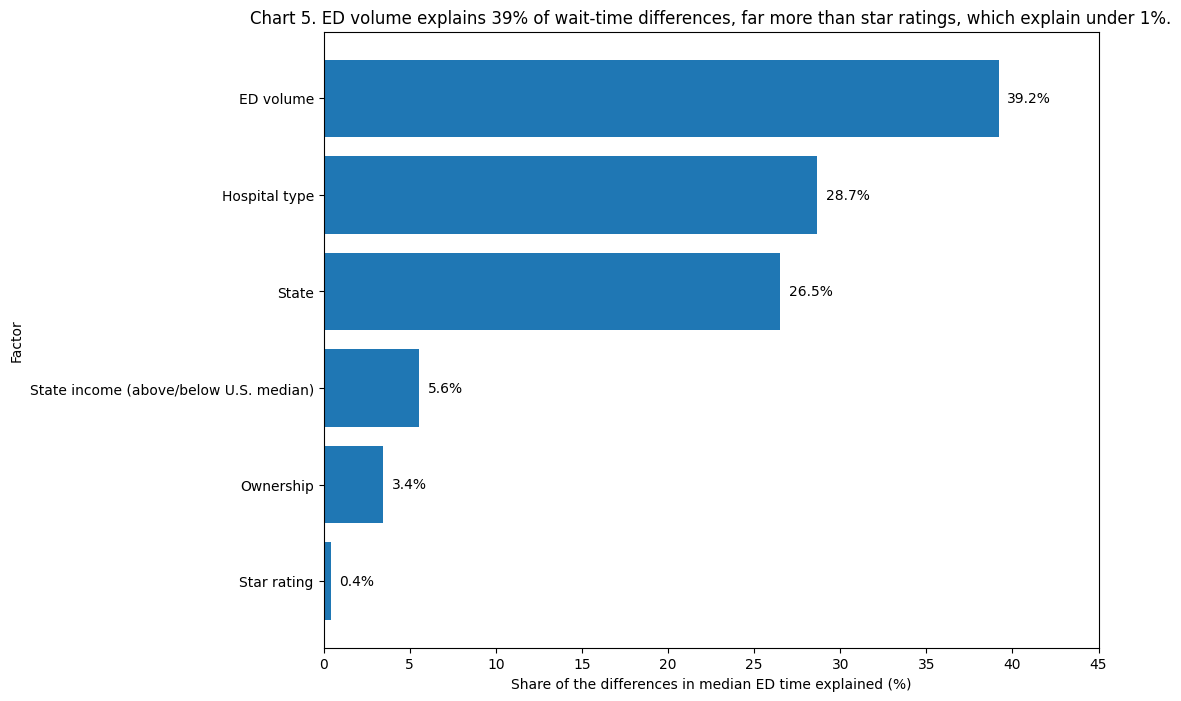

In [86]:
def impact(data, column):
    """Share of the differences in wait times explained by the groups in one column (0 = none, 1 = all)."""

    data = data.dropna(subset=[column]) # drop if factor not in hospital row

    groups = data.groupby(column)["op_18b_min"]
    group_mean = groups.transform("mean") # gives every hospital its group’s average, so each hospital sits next to the average of its own group!

    within_groups = ((data["op_18b_min"] - group_mean) ** 2).sum() # variation within groups
    total = ((data["op_18b_min"] - data["op_18b_min"].mean()) ** 2).sum() # variation across all hospitals
    return 1 - within_groups / total    # share of the variation explained by the factor: a bigger number means a bigger impact


# State income is a number, so we turn it into two groups (above or below the U.S. median)
us_income = United_States_values["median_hh_income"]
final_data["income_group"] = "Below U.S. median income"
final_data.loc[final_data["median_hh_income"] > us_income, "income_group"] = "Above U.S. median income"

factors = {"ED volume": "edv_level", "Hospital type": "hospital_type", "State": "state","State income (above/below U.S. median)": "income_group",
           "Ownership": "ownership_group", "Star rating": "hospital_overall_rating"} # used claude to write this out quickly (these are the factors i wanted to see impact of on wait times)

impact_factors = {}

for name, column in factors.items():
    impact_factors[name] = impact(final_data, column) * 100

impact_factors = pd.Series(impact_factors).sort_values()


plt.figure(figsize=(10, 8))
plt.barh(impact_factors.index, impact_factors)

for name, value in zip(impact_factors.index, impact_factors):
    plt.text(value + 0.5, name, f"{value:.1f}%", va="center") # used claude to learn how to write the % next to each bar

plt.title("Chart 5. ED volume explains 39% of wait-time differences, far more than star ratings, which explain under 1%.")
plt.xlabel("Share of the differences in median ED time explained (%)")
plt.ylabel("Factor")
plt.xlim(0, 45)
plt.show()

**Answer Q1:** **ED volume explains the most, 39% of the differences** between hospitals, followed by hospital type (29%) and state (27%). State income explains only 6%, ownership 3% and **star rating less than 1%**.

This ranking guides the rest of the analysis: we focus on ED volume and hospital type first. Since volume explains the most, we start by looking at how much waits change with ED size.

Ill start with exploring busier EDs first:

**Q2. How much longer are waits at busier EDs, and how often do they exceed four hours?**

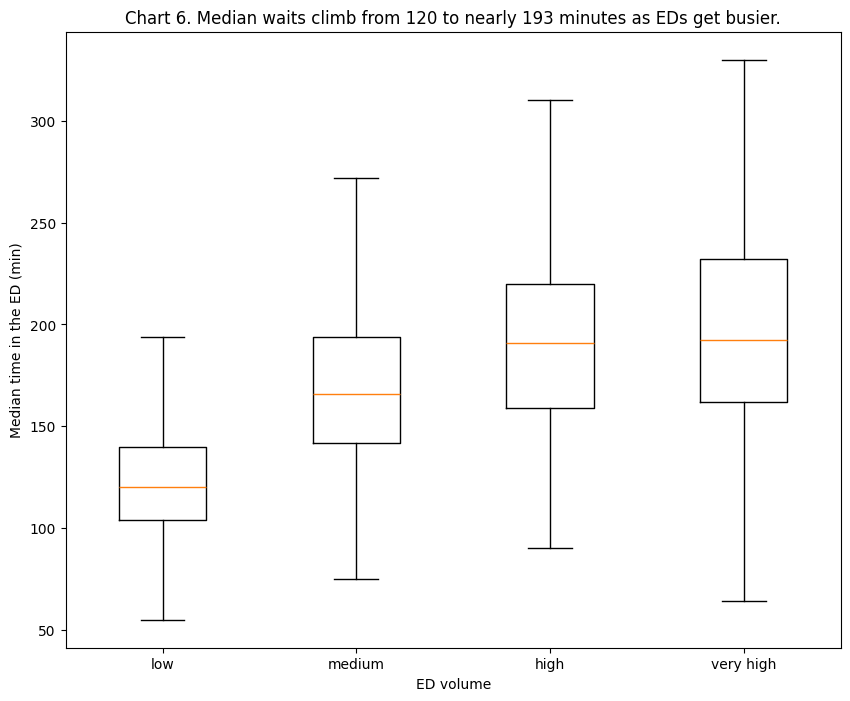

In [87]:
wait_times = []
for level in volume_order:
    wait_times.append(final_data.loc[final_data["edv_level"] == level, "op_18b_min"]) # build wait times list based on wait time at each level to illustrate

plt.figure(figsize=(10, 8))
plt.boxplot(wait_times, showfliers=False)
plt.title("Chart 6. Median waits climb from 120 to nearly 193 minutes as EDs get busier.")
plt.xlabel("ED volume")
plt.xticks([1, 2, 3, 4], volume_order)
plt.ylabel("Median time in the ED (min)")
plt.show()

final_data["four_hour_time"] = (final_data["op_18b_min"] > 240)*100     # to see which hospitals go over a huge 4 hour wait, x 100 for percebtagesss

In [88]:
summary = final_data.groupby("edv_level")["op_18b_min"].agg(["count", "median"])
summary["% over 4 hours"] = final_data.groupby("edv_level")["four_hour_time"].mean()
display(summary)

,count,median,% over 4 hours
edv_level,,,
high,551,191.00,14.16
low,1608,120.00,0.19
medium,911,166.00,3.40
very high,702,192.50,20.23


**Answer Q2:** The median wait rises from **120 minutes** at low-volume EDs (1,608 hospitals) to 166 at medium, 191 at high and **192.5 at very-high-volume EDs**.

The biggest jump in wait times is from low to medium volume (+46 minutes), while high and very-high EDs are similar, so waits seem to level off once an ED is busy. Very long waits rise even faster: only 0.2% of low-volume EDs have a median visit over four hours, compared with 14.2% of high-volume and **20.2% of very-high-volume EDs**, one in five.

Size clearly matters (lol), but small rural hospitals might be fast only because they are small, so next we compare them with hospitals of the same size.

**Q3. Are Critical Access (small rural) hospitals fast only because their EDs are small?** We compare them with other hospitals of the same ED volume (they only appear at low and medium volume).

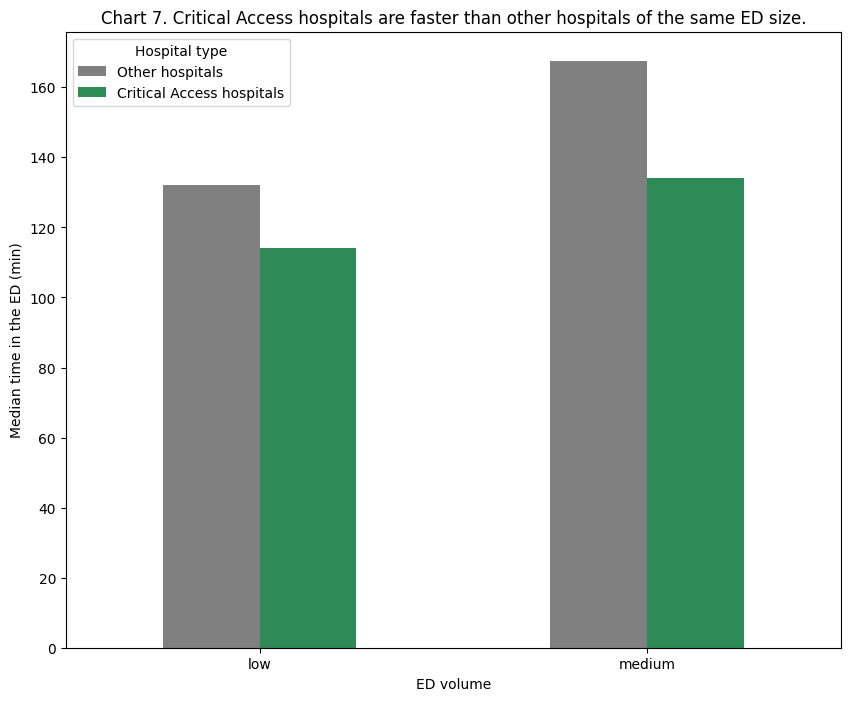

In [89]:
small_eds = final_data[final_data["edv_level"].isin(["low", "medium"])] # only look at smaller EDs!

difference = small_eds.pivot_table(index="edv_level", columns="is_critical_access",values="op_18b_min", aggfunc="median") # i studied for pivot_tables a lot for quiz 2 and finally got to actually use one in practice !

difference.columns = ["Other hospitals", "Critical Access hospitals"]

# Chart 7: Critical Access vs. other hospitals with the same ED volume
difference.plot(kind="bar", figsize=(10, 8), color=["gray", "seagreen"])
plt.title("Chart 7. Critical Access hospitals are faster than other hospitals of the same ED size.")
plt.xlabel("ED volume")
plt.ylabel("Median time in the ED (min)")
plt.xticks(rotation=0) # used claude to see how to make x label horizontal!
plt.legend(title="Hospital type")
plt.show()

**Answer Q3:** No, they are faster even at the same size, which shows that something besides size makes critical access hospitals faster. Among low-volume EDs, Critical Access hospitals have a median wait of **115 minutes vs. 130 minutes** at other hospitals , 15 minutes faster on average.

Even among the busiest EDs, median waits range from about one hour to more than five, so next we compare the fastest and slowest of them.

**Q4. Why are some busy EDs fast and others slow?** We split the very-high-volume EDs into the fastest 25%, the middle 50% and the slowest 25% by median wait, and compare the groups.

In [90]:
busy_eds = final_data[final_data["edv_level"] == "very high"].copy()

fast_cutoff = busy_eds["op_18b_min"].quantile(0.25) # i researched on claude to find a way to seperate fastest ones in my df to others, came across quantile which seperates based on %, found it a lowkey useful learning
slow_cutoff = busy_eds["op_18b_min"].quantile(0.75)
print("Fastest quarter: median wait of", fast_cutoff, "mins or less")
print("Slowest quarter: median wait of", slow_cutoff, "mins or more")

busy_eds["speed_group"] = "average"
busy_eds.loc[busy_eds["op_18b_min"] <= fast_cutoff, "speed_group"] = "Fastest 25%"
busy_eds.loc[busy_eds["op_18b_min"] >= slow_cutoff, "speed_group"] = "Slowest 25%"

busy_eds["for_profit"] = busy_eds["ownership_group"] == "For profit" # i wanna see effect on if they are for profit so seperate em from ownership group

groups = busy_eds.groupby("speed_group")

# One summary per column, combined into one table
speed_profile = pd.DataFrame({
    "hospitals": groups["op_18b_min"].count(),
    "median_wait": groups["op_18b_min"].median(),
    "psych_wait": groups["op_18c_min"].median(),
    "transfer_wait": groups["op_18d_min"].median(),
    "percentage_who_left": groups["op_22_left_pct"].mean(),
    "for_profit": groups["for_profit"].mean() * 100,
    "star_rating": groups["hospital_overall_rating"].mean()}) # used claude to build df quickly

speed_profile = speed_profile.loc[["Fastest 25%", "average", "Slowest 25%"]]
display(speed_profile.round(2))

Fastest quarter: median wait of 162.0 mins or less
Slowest quarter: median wait of 232.0 mins or more


,hospitals,median_wait,psych_wait,transfer_wait,percentage_who_left,for_profit,star_rating
speed_group,,,,,,,
Fastest 25%,177,139.00,221.50,288.50,1.23,37.85,3.15
average,347,192.00,290.00,347.00,2.22,8.36,3.25
Slowest 25%,178,261.50,368.00,415.00,3.56,2.25,3.27


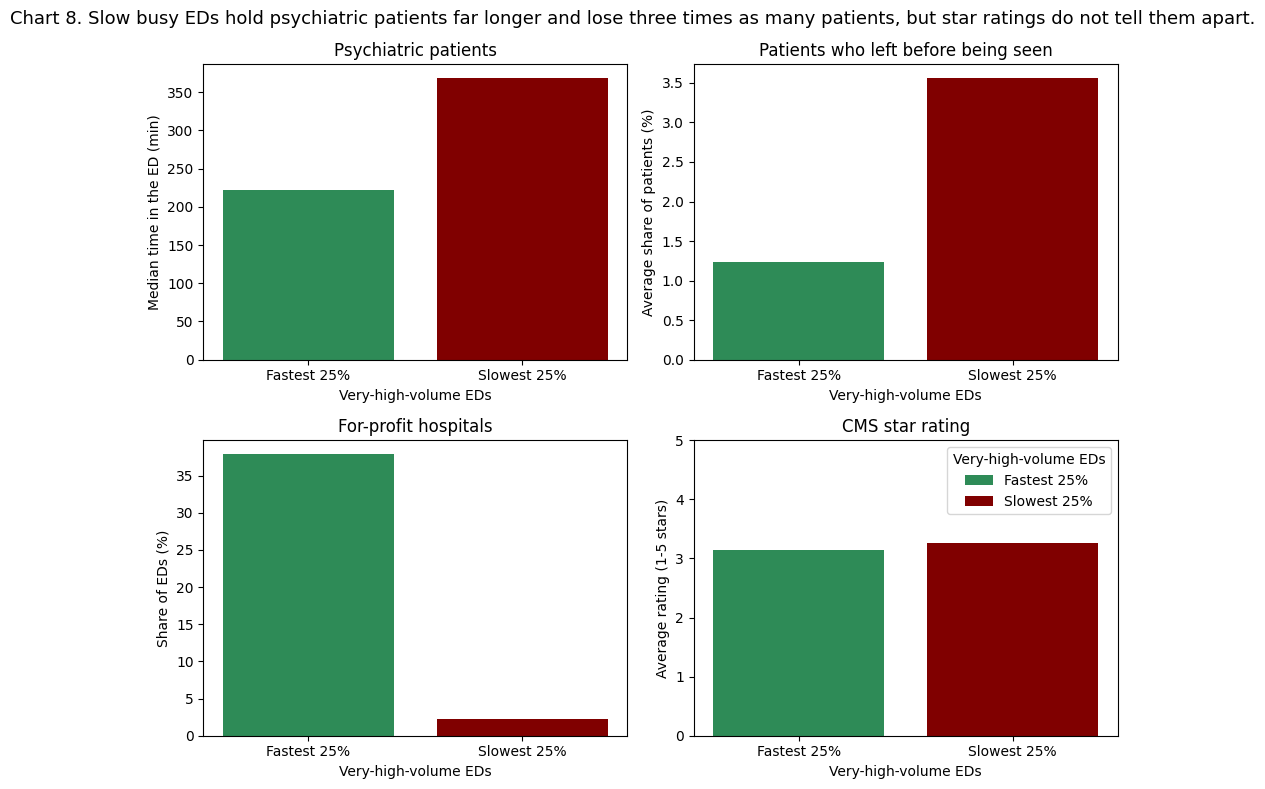

In [91]:
compare = speed_profile.loc[["Fastest 25%", "Slowest 25%"]]
colors = ["seagreen", "maroon"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

bars = axes[0, 0].bar(compare.index, compare["psych_wait"], color=colors)
axes[0, 0].set_title("Psychiatric patients")
axes[0, 0].set_ylabel("Median time in the ED (min)")

axes[0, 1].bar(compare.index, compare["percentage_who_left"], color=colors)
axes[0, 1].set_title("Patients who left before being seen")
axes[0, 1].set_ylabel("Average share of patients (%)")

axes[1, 0].bar(compare.index, compare["for_profit"], color=colors)
axes[1, 0].set_title("For-profit hospitals")
axes[1, 0].set_ylabel("Share of EDs (%)")

axes[1, 1].bar(compare.index, compare["star_rating"], color=colors)
axes[1, 1].set_title("CMS star rating")
axes[1, 1].set_ylabel("Average rating (1-5 stars)")
axes[1, 1].set_ylim(0, 5)
axes[1, 1].legend(bars, compare.index, title="Very-high-volume EDs", loc="upper right")

axes[0, 0].set_xlabel("Very-high-volume EDs")
axes[0, 1].set_xlabel("Very-high-volume EDs")
axes[1, 0].set_xlabel("Very-high-volume EDs")
axes[1, 1].set_xlabel("Very-high-volume EDs")
fig.suptitle("Chart 8. Slow busy EDs hold psychiatric patients far longer and lose three times as many patients, but star ratings do not tell them apart.", fontsize=13)
plt.tight_layout()
plt.show()

# used claude to generate this cell (replicatable axes code. i know how to write it, used ai to save time in this cell)

**Answer Q4:** The fastest quarter of very-high-volume EDs (a median wait of 162 minutes or less) and the slowest quarter (232 minutes or more) differ in clear ways.

- **Patients who need a bed or a transfer:** psychiatric patients spend a median of 221.5 minutes in the fastest EDs vs. **368 minutes** in the slowest, and transferred patients 288.5 vs. 415, which suggests slow EDs are held up by patients waiting to be admitted or moved elsewhere.

- **Patients lost:** the slowest EDs lose **three times as many patients** before they are seen (3.6% vs. 1.2%).

- **Ownership:** 37.9% of the fastest EDs are for-profit vs. only 2.2% of the slowest.

- **Quality ratings:** the average star rating is the same (3.2 vs. 3.3), so star ratings do not identify slow EDs.

If the slow EDs could catch up, how much time would patients save? This question is important to ask to evaluate whether it would have a sizable impact
or not??

Q5 estimates it.

**Q5. How many minutes per visit would patients save if the slower half of very-high-volume EDs cut their waits to the typical wait for busy EDs (192.5 minutes)?**

In [92]:
typical_wait = busy_eds["op_18b_min"].median()
slow_eds = busy_eds[busy_eds["op_18b_min"] > typical_wait]
minutes_saved = (slow_eds["op_18b_min"] - typical_wait).mean()

print("Typical wait at very-high-volume EDs:", typical_wait, "minutes")
print("EDs slower than that:", len(slow_eds))
print("Average minutes saved per visit:", round(minutes_saved))

Typical wait at very-high-volume EDs: 192.5 minutes
EDs slower than that: 351
Average minutes saved per visit: 48


**Answer Q5:** **351 very-high-volume EDs** are slower than the typical busy ED (192.5 minutes). If they cut their waits to that level, their visits would be about **48 minutes shorter** on average, which is the basis of Recommendation 1.

Part 1 showed *which hospitals* are slow. Part 2 looks at *who pays the price* for these waits.

---
## Part 2: The Patients
**Owner: Michael** · Charts 9–10 · Questions Q6–Q9

Part 1 showed *which hospitals* are slow. This part shows *who pays the price*: patients who give up and leave before being seen, and psychiatric and transferred patients, who wait the longest.

**Q6. At what wait do patients start leaving before being seen?** We group hospitals by their median wait into four bands.

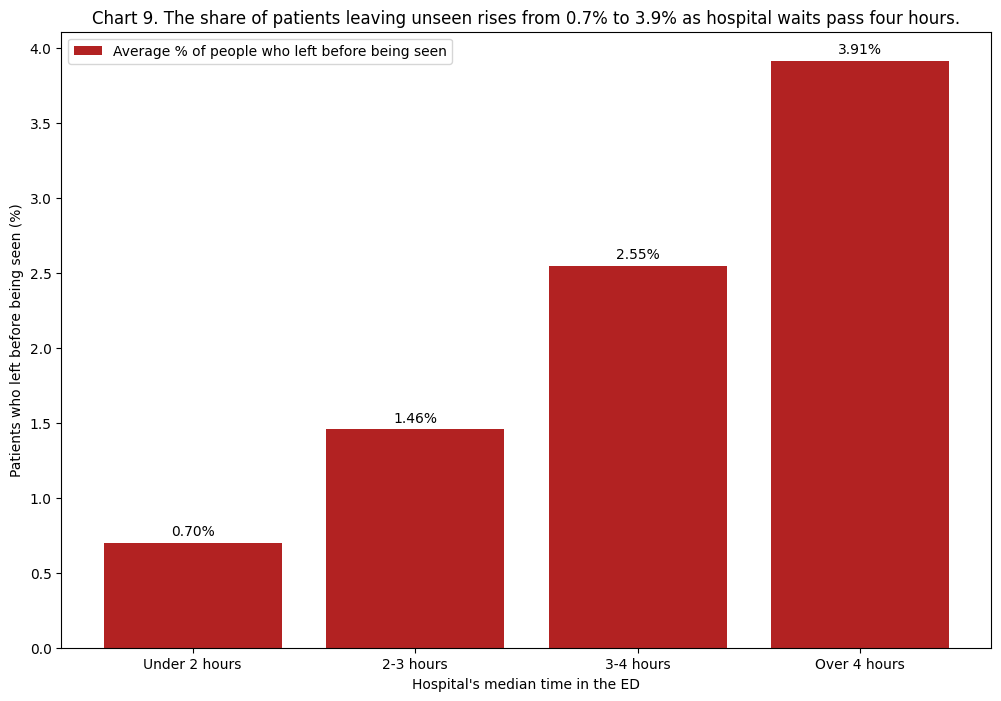

In [93]:
#Creating four different wait-groups
final_data["wait_length"] = "Under 2 hours"
final_data.loc[final_data["op_18b_min"] > 120, "wait_length"] = "2-3 hours"
final_data.loc[final_data["op_18b_min"] > 180, "wait_length"] = "3-4 hours"
final_data.loc[final_data["op_18b_min"] > 240, "wait_length"] = "Over 4 hours"

# Finding the count and the average % of patients who left before being seen
band_order = ["Under 2 hours", "2-3 hours", "3-4 hours", "Over 4 hours"]
left_before_seen = final_data.groupby("wait_length")["op_22_left_pct"].agg(["count", "mean"])
left_before_seen = left_before_seen.loc[band_order]
#bar chart
plt.figure(figsize = (12,8))

plt.bar(x = left_before_seen.index.astype(str), height = left_before_seen["mean"], color = "firebrick", label = "Average % of people who left before being seen")

# Write the value on top of each bar
for band, value in zip(left_before_seen.index.astype(str), left_before_seen["mean"]):
    plt.text(band, value + 0.05, f"{value:.2f}%", ha="center")

# Graph Labels
plt.title("Chart 9. The share of patients leaving unseen rises from 0.7% to 3.9% as hospital waits pass four hours.")
plt.xlabel("Hospital's median time in the ED")
plt.ylabel("Patients who left before being seen (%)")

plt.legend()

plt.show()

In [94]:
# Correlations
ed_correlation = final_data["op_18b_min"].corr(final_data["op_22_left_pct"])

rounded_ed_correlation = round(ed_correlation, 3)

print("The correlation is:", rounded_ed_correlation)

The correlation is: 0.522


**Answer Q6:** Yes, and there is no single cut-off point: the share of patients who leave before being seen rises with every extra hour of waiting. Hospitals with a median under 2 hours lose **0.70%** of patients, compared with 1.46% at 2–3 hours, 2.55% at 3–4 hours and **3.91% over 4 hours**, 5.6 times as many. The correlation between wait time and the share who leave is **0.52**, so roughly each extra hour of median wait adds about one percentage point of patients who leave without care.

**Q7. How many patients a year would stay to be seen if the busiest EDs over four hours moved into the 3–4 hour band?** We use the CMS minimum of **60,000 visits a year** for a very-high-volume ED, so the estimate is conservative.

In [95]:
#Wait times over 4 hours
over_4_hours = final_data[(final_data["edv_level"] == "very high") & (final_data["op_18b_min"] > 240)]

#Difference in % leaving between leaving over 4 hours and between 3-4 hours
drop_in_left_percentage = (left_before_seen.loc["Over 4 hours", "mean"] - left_before_seen.loc["3-4 hours", "mean"])

# How many patients would actually stay and get seen
patients_stay_seen = len(over_4_hours) * 60000 * drop_in_left_percentage / 100

print("The number of EDs is:", len(over_4_hours))
print("The percentage drop in patients leaving is:", round(drop_in_left_percentage,2))
print("The number of patients that would actually stay is approximately:", round(patients_stay_seen,2))

The number of EDs is: 142
The percentage drop in patients leaving is: 1.37
The number of patients that would actually stay is approximately: 116338.17


**Answer Q7:** About **116,338 patients a year** would stay to be seen if the 142 very-high-volume EDs with a median over four hours moved into the 3–4 hour band, which lowers the share who leave by 1.37 percentage points. The estimate is conservative because it assumes each of these EDs has only 60,000 visits a year, the minimum for the very-high-volume category, and it only counts very-high-volume EDs rather than every hospital with long waits.

**Q8. Do psychiatric and transferred patients wait even longer at busier EDs, and where is the psychiatric gap largest?**

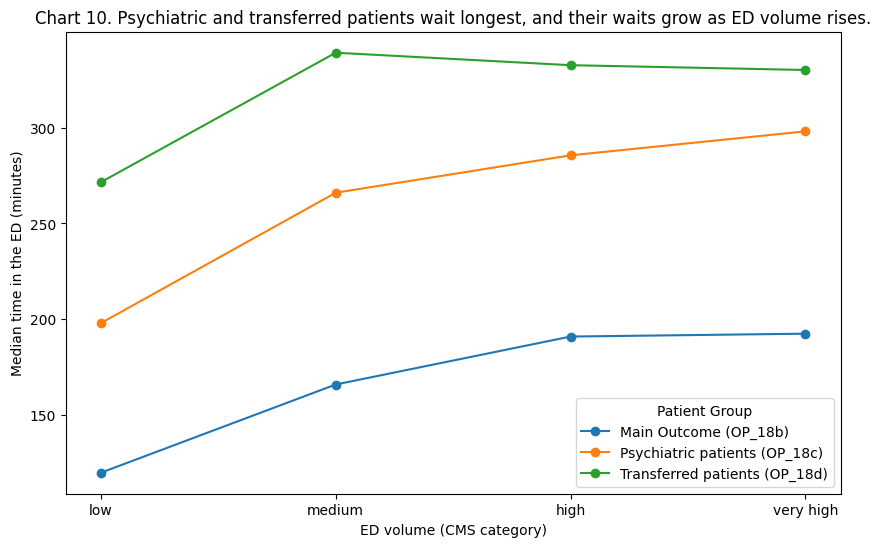

In [96]:
# Median wait times for each patient group by ED volume
patient_groups = final_data.groupby("edv_level")[["op_18b_min", "op_18c_min", "op_18d_min"]].median()

# Make sure the order is right in volume order (low, medium, high, very high)
patient_groups = patient_groups.loc[volume_order]

# Naming the columns
patient_groups.columns = ["Main Outcome (OP_18b)", "Psychiatric patients (OP_18c)", "Transferred patients (OP_18d)"]

# Creating graph
patient_groups.plot(kind = "line", marker = "o", figsize = (10,6))

# Label positions as Low, Medium, High, Very High
plt.xticks([0,1,2,3], volume_order)

# Creating graph
plt.title("Chart 10. Psychiatric and transferred patients wait longest, and their waits grow as ED volume rises.")
plt.xlabel("ED volume (CMS category)")
plt.ylabel("Median time in the ED (minutes)")
plt.legend(title = "Patient Group")
plt.show()

In [97]:
#Psychiatric Wait time gaps
final_data["psych_gap"] = (final_data["op_18c_min"] - final_data["op_18b_min"])

psych_states = final_data.groupby("state")["psych_gap"].agg(["count", "median"])

# Keep states with at least 5 hospitals (with fewer, one hospital decides the median)
psych_states = psych_states[psych_states["count"] >= 5]

psych_states = psych_states.sort_values("median")

#Combine the three largest states with the highest median wait-time gaps with the 3 smallest states
pd.concat([psych_states.head(3), psych_states.tail(3)])

,count,median
state,,
SD,39,35.00
DC,5,37.00
ND,32,43.00
TN,78,134.00
MA,52,156.50
VT,7,209.00


**Answer Q8:** Busier EDs have longer patient stays, with transferred and psychiatric patients spending the most time in the ED.

Transferred patients have the longest stays at every volume level (low, medium, high, and very high) although their times peak at medium volume and then decrease slightly. The states with the smallest psych wait time gaps are SD (South Dakota) at 35 mins, DC at 37 mins, and ND (North Dakota) at 43 minutes. The states with the largest wait time gaps are TN (Tennesse) at 143 minutes, MA (Massachusetts) at 156.5 minutes, and VT (Vermont) at 209 minutes. However, one thing to note: both DC and Vermont only have 5 and 7 hospitals, respectively.

**Q9. How many minutes would psychiatric patients save if busy EDs had the same psychiatric gap as small EDs?**

In [98]:
#Median psychiatric wait time gap by ED volume
psych_gap_by_volume = final_data.groupby("edv_level")["psych_gap"].median()

#Difference between very-high volume and low-volume EDs
number_of_minutes_saved = (psych_gap_by_volume["very high"] - psych_gap_by_volume["low"])

rounded_number_of_minutes_saved = round(number_of_minutes_saved,2)

print("The minutes saved per psychiatric patient is:", rounded_number_of_minutes_saved)

The minutes saved per psychiatric patient is: 24.5


**Answer Q9:** Psychiatric patients at very-high-volume EDs could save about **25 minutes** each (24.5) if the psychiatric gap at these EDs matched the gap at low-volume EDs. This supports Recommendation 3: building better behavioral-health pathways at busy EDs would cut these delays.

---
## Part 3: Owners and Rural States
**Owner: Weiran Wang** · Charts 11–12 · Questions Q10–Q13

Part 1 showed that size matters most. This part asks whether *who owns* the hospital and its quality rating matter once size is the same, finds the fastest busy EDs as benchmarks, and then moves from hospitals to states by asking whether rural states are faster.

**Q10. Does ownership matter once we compare EDs of the same size?** Federal and Tribal hospitals are left out because there are too few of them at each volume level.

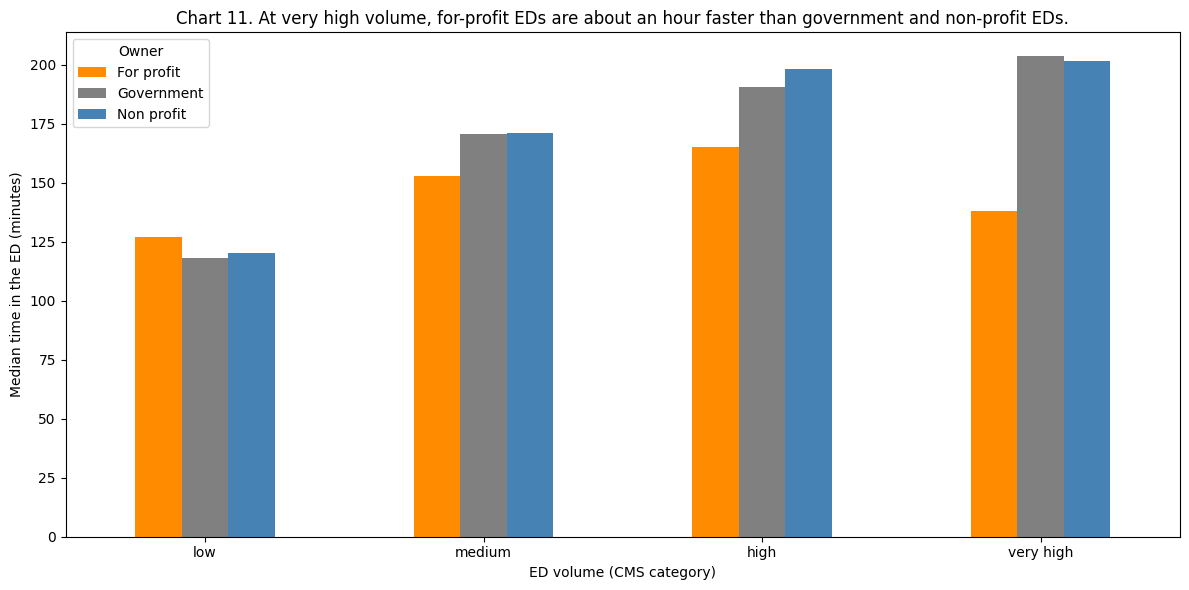

Median ED time (minutes):


ownership_group,For profit,Government,Non profit
edv_level,,,
low,127.00,118.00,120.00
medium,153.00,170.50,171.00
high,165.00,190.50,198.00
very high,138.00,203.50,201.50


Number of hospitals with a reported ED time:


ownership_group,For profit,Government,Non profit
edv_level,,,
low,220,479,892
medium,186,96,611
high,96,52,396
very high,100,114,484


In [99]:
# Compare ownership within each volume group.
# Keep the three main ownership groups.
main_owners = final_data[
    final_data["ownership_group"].isin(["For profit", "Government", "Non profit"])].copy()

# Median time by volume and owner.
owner_order = ["For profit", "Government", "Non profit"]
owner_volume = main_owners.groupby(["edv_level", "ownership_group"])["op_18b_min"].median().unstack()

# Keep the volume and owner order consistent.
owner_volume = owner_volume.loc[volume_order, owner_order]

# Chart 11.
ax = owner_volume.plot(kind="bar", figsize=(12, 6), color=["darkorange", "gray", "steelblue"])

ax.set_title("Chart 11. At very high volume, for-profit EDs are about an hour faster than government and non-profit EDs.")

ax.set_xlabel("ED volume (CMS category)")
ax.set_ylabel("Median time in the ED (minutes)")
ax.legend(title="Owner")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Check the number of hospitals in each group.
owner_counts = main_owners.groupby(["edv_level", "ownership_group"])["op_18b_min"].count().unstack()
owner_counts = owner_counts.loc[volume_order, owner_order]

print("Median ED time (minutes):")
display(owner_volume.round(1))
print("Number of hospitals with a reported ED time:")
display(owner_counts)

**Answer Q10:** Ownership differences are small at low volume: the medians are 127 minutes for for-profit hospitals, 118 for government hospitals and 120 for non-profit hospitals. At very high volume, the for-profit median is 138 minutes, compared with 203.5 for government and 201.5 for non-profit hospitals—about an hour shorter. This suggests that the ownership difference is larger among busy EDs, although differences in location and patient mix could also help explain it.

**Q11. Do hospitals with higher star ratings have shorter waits?**

In [100]:
# Compare ratings with ED time.
# Keep missing ratings as missing.
ratings = final_data["hospital_overall_rating"].astype(float)
rating_correlation = ratings.corr(final_data["op_18b_min"])

print(f"Correlation between star rating and ED time: {rating_correlation:.2f}")
print("Hospitals with a star rating:", ratings.notna().sum())
print("Hospitals without a star rating:", ratings.isna().sum())

# Median time by volume and star rating.
rating_volume = final_data.groupby(
    ["edv_level", "hospital_overall_rating"]
)["op_18b_min"].median().unstack()
rating_volume = rating_volume.loc[volume_order, [1, 2, 3, 4, 5]]

print("Median ED time (minutes), by volume and star rating:")
display(rating_volume.round(1))

# Check the group sizes.
rating_counts = final_data.groupby(
    ["edv_level", "hospital_overall_rating"]
)["op_18b_min"].count().unstack()

rating_counts = rating_counts.loc[volume_order, [1, 2, 3, 4, 5]]
print("Number of hospitals in each rated group:")
display(rating_counts)

Correlation between star rating and ED time: -0.04
Hospitals with a star rating: 2965
Hospitals without a star rating: 1115
Median ED time (minutes), by volume and star rating:


hospital_overall_rating,1,2,3,4,5
edv_level,,,,,
low,131.50,136.00,133.00,130.00,127.00
medium,174.00,174.00,168.50,162.00,163.00
high,198.00,182.00,193.00,193.50,191.00
very high,197.00,194.00,190.00,188.00,206.50


Number of hospitals in each rated group:


hospital_overall_rating,1,2,3,4,5
edv_level,,,,,
low,52,165,227,226,78
medium,59,186,276,261,83
high,31,125,167,156,64
very high,37,143,225,201,88


**Answer Q11:** Higher star ratings do not consistently go with shorter ED times in this sample. The overall correlation is −0.04, and among very-high-volume EDs, the median is 197 minutes for 1-star hospitals and 206.5 minutes for 5-star hospitals. I would therefore not use the overall star rating alone to judge ED speed. There are also 1,115 hospitals without ratings, so they are not included in the rating comparisons.

**Q12. Which very-high-volume EDs manage the shortest waits?** These are possible benchmarks for other busy EDs.

In [101]:
# Find the shortest times among very-high-volume EDs.
busiest_eds = final_data[final_data["edv_level"] == "very high"].copy()

# Take the first five after sorting by time.
# Use facility ID to order tied times.
fastest_five = busiest_eds.sort_values(["op_18b_min", "facility_id"]).head(5)

benchmark_columns = ["facility_name", "state", "ownership_group", "op_18b_min", "op_22_left_pct"]

display(fastest_five[benchmark_columns])

# Compare with the group median.
busy_median = busiest_eds["op_18b_min"].median()
for_profit_count = (fastest_five["ownership_group"] == "For profit").sum()
print(f"Median ED time for all very-high-volume EDs: {busy_median:.1f} minutes")
print(f"For-profit hospitals among the five listed: {for_profit_count}")

,facility_name,state,ownership_group,op_18b_min,op_22_left_pct
2916,INTEGRIS COMMUNITY HOSPITAL - COUNCIL CROSSING,OK,For profit,64.00,2.00
2063,RESEARCH MEDICAL CENTER,MO,For profit,90.00,0.00
2308,SAINT ROSE DOMINICAN HOSPITALS - NORTH LAS VEGAS,NV,For profit,91.00,1.00
142,DIGNITY HEALTH ARIZONA GENERAL HOSPITAL,AZ,Non profit,92.00,1.00
4060,THE HOSPITALS OF PROVIDENCE HORIZON CITY CAMPUS,TX,For profit,92.00,0.00


Median ED time for all very-high-volume EDs: 192.5 minutes
For-profit hospitals among the five listed: 4


**Answer Q12:** The five hospitals listed above have median ED times of 64–92 minutes, compared with 192.5 minutes for the full very-high-volume group. Four are for-profit hospitals, and their reported percentages of patients leaving before being seen range from 0% to 2%. They could be useful hospitals to study further, but these data do not tell us which practices explain their shorter times or whether their patients are comparable to those at other busy EDs.

**Q13. Do states that rely on small rural hospitals have shorter waits?** We summarize each state by the median of its hospitals (Puerto Rico and states with fewer than 5 hospitals are left out).

Number of states, including D.C.: 51
Correlation: -0.72


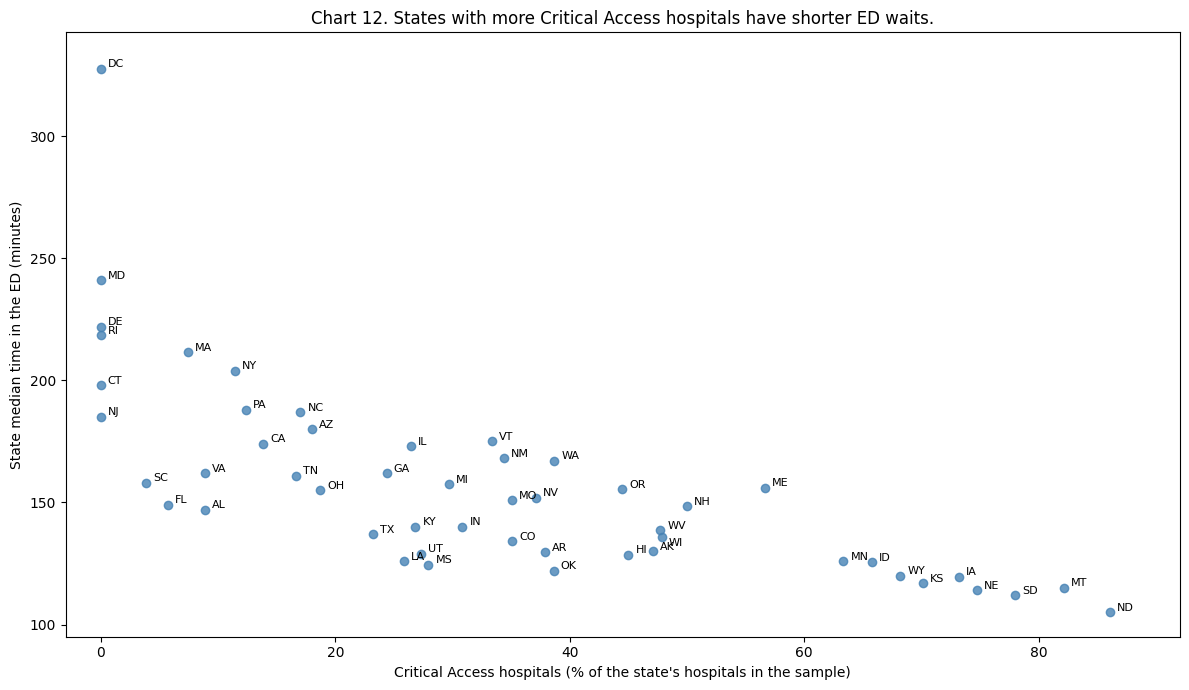

Five states with the shortest median ED times:


,hospitals,median_wait,pct_critical_access
state,,,
ND,43,105.00,86.00
SD,50,112.00,78.00
NE,83,114.00,74.70
MT,56,115.00,82.10
KS,117,117.00,70.10


Five states with the longest median ED times:


,hospitals,median_wait,pct_critical_access
state,,,
DC,6,327.50,0.00
MD,40,241.00,0.00
DE,6,222.00,0.00
RI,10,218.50,0.00
MA,54,211.50,7.40


In [102]:
# Compare Critical Access share with state ED time.
# Summarize by state, excluding Puerto Rico.
state_hospitals = final_data[final_data["state"] != "PR"].copy()

# Group the hospitals by state
state_groups = state_hospitals.groupby("state")

# One summary per column, combined into one table
rural_states = pd.DataFrame({
    "hospitals": state_groups["op_18b_min"].count(),
    "median_wait": state_groups["op_18b_min"].median(),
    "pct_critical_access": state_groups["is_critical_access"].mean()})

# The mean of a True/False column gives the share.
# Convert to percent and keep states with at least five hospitals.
rural_states["pct_critical_access"] = rural_states["pct_critical_access"] * 100
rural_states = rural_states[rural_states["hospitals"] >= 5].copy()

# Calculate the state-level correlation.
rural_correlation = rural_states["pct_critical_access"].corr(
    rural_states["median_wait"])

print("Number of states, including D.C.:", len(rural_states))
print(f"Correlation: {rural_correlation:.2f}")

# Chart 12.
plt.figure(figsize=(12, 7))
plt.scatter(
    rural_states["pct_critical_access"], rural_states["median_wait"],
    color="steelblue", alpha=0.8)

for state in rural_states.index:
    x = rural_states.loc[state, "pct_critical_access"]
    y = rural_states.loc[state, "median_wait"]
    # Move WI down so its label does not overlap WV.
    if state == "WI":
        plt.text(x + 0.6, y - 4, state, fontsize=8)
    else:
        plt.text(x + 0.6, y + 0.6, state, fontsize=8)

plt.title("Chart 12. States with more Critical Access hospitals have shorter ED waits.")

plt.xlabel("Critical Access hospitals (% of the state's hospitals in the sample)")
plt.ylabel("State median time in the ED (minutes)")
plt.xlim(-3, rural_states["pct_critical_access"].max() + 6)
plt.ylim(rural_states["median_wait"].min() - 10, rural_states["median_wait"].max() + 15)
plt.tight_layout()
plt.show()

# Check the states with the shortest and longest times.
states_by_wait = rural_states.sort_values("median_wait")
print("Five states with the shortest median ED times:")
display(states_by_wait.head(5).round(1))
print("Five states with the longest median ED times:")
display(states_by_wait.tail(5).sort_values("median_wait", ascending=False).round(1))

**Answer Q13:** States where Critical Access hospitals make up a larger percentage of the hospital sample tend to have shorter median ED times. The correlation is −0.72, showing a strong negative relationship: as the Critical Access share increases, ED time generally decreases. For example, North Dakota has an 86% share and a median ED time of 105 minutes, while Maryland has a 0% share and a median of 241 minutes. This pattern shows an association, but other differences between states may also contribute.

---
## Part 4: States and the Economy
**Owner: Aashna Pathi** · Charts 13–15 · Questions Q14–Q18

Part 3 showed that rural states are faster. This part asks whether the states with the strongest economies also have the shortest waits, using two U.S. maps, a regression and a side-by-side case study of Massachusetts and Minnesota.

We first build a state table: Puerto Rico and states with fewer than 5 hospitals are left out, which leaves the 50 states and D.C.

In [103]:
states = final_data[final_data['state'] != "PR"]

state_groups = states.groupby("state")
state_columns = ["median_hh_income", "commute_min", "public_transit_pct", "unemployment_pct",
                 "uninsured_pct", "public_insurance_pct", "poverty_pct"]
state_table = state_groups[state_columns].mean()

# Hospital summaries for each state
state_table["hospitals"] = state_groups["op_18b_min"].count()
state_table["median_wait"] = state_groups["op_18b_min"].median()
state_table["pct_critical_access"] = state_groups["is_critical_access"].mean()

state_table['pct_critical_access'] = state_table['pct_critical_access'] * 100
state_table = state_table[state_table['hospitals'] >= 5]
print("Number of states with more than 4 hospitals: ", state_table.shape[0])
display(state_table.head(3))

Number of states with more than 4 hospitals:  51


,median_hh_income,commute_min,public_transit_pct,unemployment_pct,uninsured_pct,public_insurance_pct,poverty_pct,hospitals,median_wait,pct_critical_access
state,,,,,,,,,,
AK,"95,665.00",19.80,0.70,6.00,11.00,37.80,10.20,17,130.00,47.06
AL,"66,659.00",26.00,0.40,4.20,8.20,37.90,15.20,79,147.00,8.86
AR,"62,106.00",22.70,0.30,3.80,9.40,42.60,15.50,66,129.50,37.88


**Q14. Do the states with the strongest economies have the shortest waits?**

---

Chart 13 colors each state by its median ED time and Chart 14 by its median household income. If strong economies meant shorter waits, the dark blue states in Chart 14 would be green in Chart 13.

# Note: run the next 2 cells to see the US Map output in colab, it shows automatically in vs code but for colab run file to see these 2 charts

In [104]:
state_maps = state_table.reset_index()

fig = px.choropleth(state_maps, locations="state", locationmode="USA-states", scope="usa",
                    color="median_wait", color_continuous_scale="RdYlGn_r", range_color=[100, 250],
                    labels={"median_wait": "Median ED time (min)"},
                    title="Chart 13. The longest ED waits are in DC, MD, and MA, while Plains and Southern states are fastest.",
                    width=1000, height=800)

fig.show()

In [105]:
fig2 = px.choropleth(state_maps, locations="state", locationmode="USA-states", scope="usa",
                     color="median_hh_income", color_continuous_scale="Blues",
                     labels={"median_hh_income": "Median household income ($)"},
                     title="Chart 14. The richest states (DC, MD, MA) are the same ones with the longest ED waits.",
                     width=1000, height=800)

fig2.show()

In [106]:
corr_with_median_wait = state_table[['pct_critical_access', 'commute_min', 'public_transit_pct', 'median_hh_income', 'unemployment_pct', 'uninsured_pct', 'public_insurance_pct',
             'poverty_pct', 'median_wait']].corr()["median_wait"].drop("median_wait")
corr_with_median_wait = corr_with_median_wait.sort_values()
display(corr_with_median_wait)

,median_wait
pct_critical_access,-0.72
uninsured_pct,-0.33
poverty_pct,0.07
public_insurance_pct,0.15
unemployment_pct,0.44
median_hh_income,0.51
public_transit_pct,0.70
commute_min,0.71


**Answer Q14:** No, states with the strongest economies don't always have the shortest wait times. The two maps mirror each other (dark, rich D.C./MD/MA/NJ are red, light Plains/Southern states are green). Higher-income states tend to have longer ED waits. From the correlation analysis, we can see how median household income correlates about +0.51 with median wait and unemployment correlated positively (+0.44). A weaker economy does not mean longer waits. The stronger drivers are urban density (commute time +0.71, public transit +0.70) and rural critical-access hospitals (−0.72), which go with short waits. However, this analysis can only confirm association, this does not mean that stronger economies cause longer wait times.

**Q15. How strongly are economic conditions and wait times related? (linear regression, state level)**

A linear regression fits the straight line that best predicts a state's median wait from its median household income. The slope is the change in minutes for every extra \$10,000 of income, and R² is how much of the differences between states the line explains. The dashed lines split the states into four groups at the U.S. median income and the U.S. median ED time.

In [107]:
X_state = state_table[["median_hh_income"]] / 10000
y_state = state_table["median_wait"]

## Creating an instance of LinearRegression Class
income_model = LinearRegression()

## Fit model to X and Y values
income_model.fit(X_state, y_state)

## Use the model to predict
state_table["predicted_wait"] = income_model.predict(X_state)
national_median_wait = final_data["op_18b_min"].median()

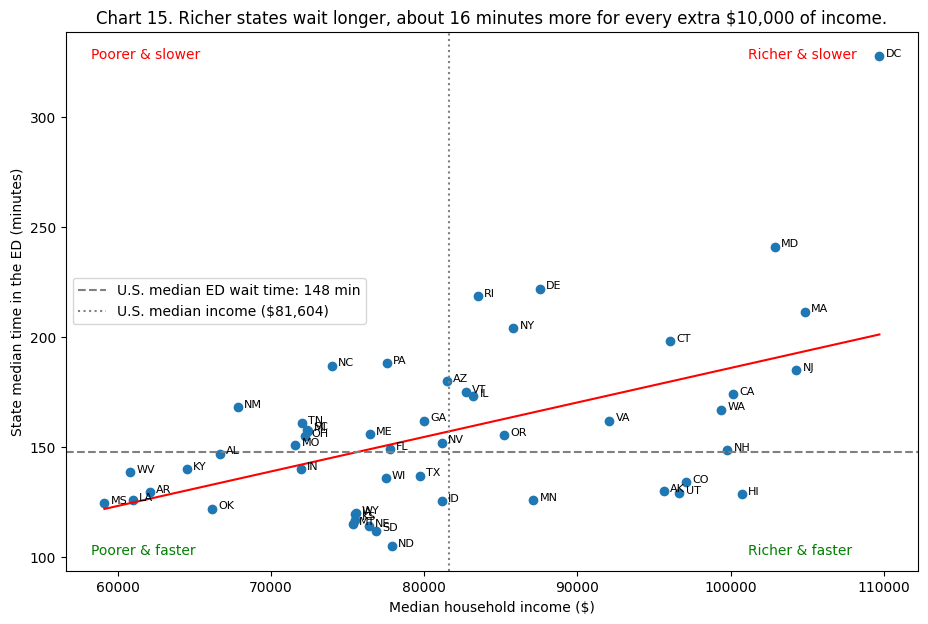

Linear Regression Equation: y = 15.66x + 29.31
Slope: 15.66
R-squared: 0.26


In [108]:
## Sorting table by median household income
sorted_state_table = state_table.sort_values("median_hh_income")

## Building Chart 15
plt.figure(figsize=(11,7))
plt.scatter(state_table["median_hh_income"], state_table["median_wait"])

## Labeling all states on the chart
for i in state_table.index:
    plt.text(state_table.loc[i, "median_hh_income"] + 400,
            state_table.loc[i, "median_wait"],
            i, fontsize=8)

plt.plot(sorted_state_table["median_hh_income"], sorted_state_table["predicted_wait"], color="red")
plt.axhline(national_median_wait, color="gray", linestyle="--", label=f"U.S. median ED wait time: {national_median_wait:.0f} min")

ax = plt.gca()
plt.text(0.03, 0.95, "Poorer & slower", color="red", transform=ax.transAxes)
plt.text(0.80, 0.95, "Richer & slower", color="red", transform=ax.transAxes)
plt.text(0.03, 0.03, "Poorer & faster", color="green", transform=ax.transAxes)
plt.text(0.80, 0.03, "Richer & faster", color="green", transform=ax.transAxes)

plt.axvline(United_States_values["median_hh_income"], color="gray", linestyle=":", label="U.S. median income ($81,604)")
plt.title("Chart 15. Richer states wait longer, about 16 minutes more for every extra $10,000 of income.")
plt.xlabel("Median household income ($)")
plt.ylabel("State median time in the ED (minutes)")
plt.legend()
plt.show()

## Print slope, R-squared, Linear Regression Equation
slope = income_model.coef_[0]
y_int = income_model.intercept_
print(f"Linear Regression Equation: y = {slope:.2f}x + {y_int:.2f}")
print(f"Slope: {slope :.2f}")
print(f"R-squared: {income_model.score(X_state, y_state) :.2f}")

In [109]:
state_maps["income_level"] = np.where(state_maps["median_hh_income"] > United_States_values["median_hh_income"], "Richer", "Poorer")
state_maps["wait_level"] = np.where(state_maps["median_wait"] > national_median_wait, "slower", "faster")
state_maps["group"] = state_maps["income_level"] + " & " + state_maps["wait_level"]

income_groups = state_maps.groupby("group")
income_wait_groups = pd.DataFrame({
    "states": income_groups["state"].count(),
    "median_wait": income_groups["median_wait"].median(),
    "state_list": income_groups["state"].apply(", ".join)})

display(income_wait_groups)

def lin_reg_model(X_value):
  y_value = state_table["median_wait"]
  ## Creating an instance of LinearRegression Class
  income_model = LinearRegression()
  ## Fit model to X and Y values
  income_model.fit(X_value, y_value)
  return income_model

print("Comparing 3 linear regression models predicting state median ED wait using different sets of features\n")
for feature, feature_list in {'Income Only' : ['median_hh_income'], 'All economic indicators' : ['median_hh_income', 'unemployment_pct', 'uninsured_pct', 'poverty_pct', 'public_insurance_pct'],
                'Economic indicators + critical access' : ['median_hh_income', 'unemployment_pct', 'uninsured_pct', 'poverty_pct', 'public_insurance_pct', 'pct_critical_access']}.items():
                reg_model = lin_reg_model(X_value = state_table[feature_list])

                print(f"Feature: {feature}")
                print(f"Income coefficient: {reg_model.coef_[0] * 10000 :.2f}")
                print(f"R-squared: {reg_model.score(state_table[feature_list], state_table['median_wait']) :.2f}")
                print('\n')

,states,median_wait,state_list
group,,,
Poorer & faster,18,125.00,"AL, AR, IA, ID, IN, KS, KY, LA, MS, MT, ND, NE, OK, SD, TX, WI, WV, WY"
Poorer & slower,13,158.00,"AZ, FL, GA, ME, MI, MO, NC, NM, NV, OH, PA, SC, TN"
Richer & faster,5,129.00,"AK, CO, HI, MN, UT"
Richer & slower,15,185.00,"CA, CT, DC, DE, IL, MA, MD, NH, NJ, NY, OR, RI, VA, VT, WA"


Comparing 3 linear regression models predicting state median ED wait using different sets of features

Feature: Income Only
Income coefficient: 15.66
R-squared: 0.26


Feature: All economic indicators
Income coefficient: 21.22
R-squared: 0.55


Feature: Economic indicators + critical access
Income coefficient: 16.89
R-squared: 0.72




**Answer Q15:** Income appears to be moderately correlated with ED waits. Income alone gives a slope of about +16 minutes per $10,000 with R² = 0.26. This is seen in the four groups in Chart 15: 15 states are "richer & slower" (median 185 min, including MA, NJ, MD, CA and DC) and only 5 are "richer & faster" (AK, CO, HI, MN, UT). When looking at all economic indicators, R² rises to 0.55 and 0.72 once the Critical Access (rural) share is added. Overall, analysis shows that a strong economy does not buy shorter waits. Rurality explains far more, though this is based on only 51 states with related indicators.

### Case Study: Massachusetts vs. Minnesota
Massachusetts and Minnesota are both **richer-than-average states with low uninsured rates**, yet they sit in opposite corners of Chart 15. Comparing them side by side shows *why* two similar economies end up with very different ED waits.

**Q16. How do Massachusetts and Minnesota compare on the factors that drive wait times?**

In [110]:
final_data["over_4_hours"] = final_data['op_18b_min'] > 240
final_data["psych_gap"] = final_data['op_18c_min'] - final_data['op_18b_min']

def state_profile(data):
    return pd.Series({
        "Hospitals": len(data),
        "Median ED time (min)": data["op_18b_min"].median(),
        "EDs with a median over 4 hours (%)": data["over_4_hours"].mean() * 100,
        "Patients who left before being seen (%)": data["op_22_left_pct"].mean(),
        "Psychiatric patients median ED time (min)": data["op_18c_min"].median(),
        "Psychiatric gap (min)": data["psych_gap"].median(),
        "High or very-high-volume EDs (% of hospitals)": data["edv_level"].str.lower().isin(["high", "very high"]).mean() * 100,
        "Critical Access hospitals (%)": data["is_critical_access"].mean() * 100,
        "For-profit hospitals (%)": (data["ownership_group"] == "For profit").mean() * 100,
        "Average star rating": data["hospital_overall_rating"].mean(),
    })

profile = pd.DataFrame({
    "Massachusetts": state_profile(final_data[final_data["state"] == "MA"]),
    "Minnesota": state_profile(final_data[final_data["state"] == "MN"]),
    "United States": state_profile(final_data),
})
display(profile.round(1))

MA_MN_table = state_table.loc[["MA", "MN"], ["median_hh_income", "uninsured_pct", "poverty_pct", "commute_min", "public_transit_pct"]]
display(MA_MN_table)

,Massachusetts,Minnesota,United States
Hospitals,54.00,120.00,"4,080.00"
Median ED time (min),211.50,126.00,148.00
EDs with a median over 4 hours (%),31.50,1.70,6.40
Patients who left before being seen (%),4.00,1.20,1.70
Psychiatric patients median ED time (min),346.00,216.00,247.00
Psychiatric gap (min),156.50,72.00,83.00
High or very-high-volume EDs (% of hospitals),57.40,15.00,30.70
Critical Access hospitals (%),7.40,63.30,30.70
For-profit hospitals (%),11.10,0.80,15.50
Average star rating,3.20,3.70,3.20


,median_hh_income,uninsured_pct,poverty_pct,commute_min,public_transit_pct
state,,,,,
MA,"104,828.00",2.80,9.70,30.60,7.80
MN,"87,117.00",5.10,9.30,22.70,1.80


**Answer Q16:** Massachusetts and Minnesota both have high incomes (MA: $104,828.00, MN: 87,117.00) and low uninsured rates (2.8% in MA, 5.1% in MN), but their hospitals differ a lot. MA's median ED time is 211.5 min against 126 for MN, and 31.5% of MA's EDs have a median over 4 hours against 1.7% in MN. MA is mostly high-volume EDs (57.4% vs 15%) and has few Critical Access hospitals (7.4% vs 63.3%), while MN has many small rural ones. MA also has more walkouts (4.0% vs 1.2%) and a 346-min psychiatric wait against 216 in MN. Star ratings (3.2 in MA, 3.7 in MN) don't explain the gap.

**Q17. Is each state fast or slow only because of its mix of hospitals?** We compare EDs of the same volume.

In [111]:
ED_volume_table = final_data.groupby(['edv_level','state'])['op_18b_min'].median().unstack()[['MA','MN']]
ED_volume_table["U.S."] = final_data.groupby('edv_level')['op_18b_min'].median()
ED_volume_table = ED_volume_table.loc[['low','medium','high','very high']]
display(ED_volume_table)

state,MA,MN,U.S.
edv_level,,,
low,165.50,120.00,120.00
medium,206.50,158.00,166.00
high,237.50,188.00,191.00
very high,241.00,204.00,192.50


**Answer Q17:** No. Hospital mix alone doesn't explain it, at least for Massachusetts.
Looking at EDs of the same volume, Massachusetts is slower than the U.S. median at every level: low 165.5 vs 120, medium 206.5 vs 166, high 237.5 vs 191, and very high 241 vs 192.5. That is about 40 to 49 minutes slower, so MA's long waits aren't just because it has more busy EDs.
Minnesota is about the same as the U.S. at each level (120 vs 120, 158 vs 166, 188 vs 191), and slower at very high volume (204 vs 192.5). Its hospitals aren't faster than average at the same size, so its lower overall wait isn't coming from faster EDs within each volume level.

**Q18. Where are Massachusetts' longest waits?**

In [112]:
MA_sorted = final_data[final_data['state'] == 'MA']
MA_sorted = MA_sorted[['state','facility_name', 'edv_level', 'op_18b_min', 'op_18c_min', 'op_22_left_pct']].sort_values(by='op_18b_min', ascending = False)
display(MA_sorted.head(5))

,state,facility_name,edv_level,op_18b_min,op_18c_min,op_22_left_pct
1725,MA,BETH ISRAEL DEACONESS MEDICAL CENTER,high,336.00,314.00,2.00
1732,MA,BRIGHAM AND WOMEN'S HOSPITAL,very high,300.00,274.00,5.00
1737,MA,UMASS MEMORIAL MEDICAL CENTER/UNIVERSITY CAMPUS,very high,291.00,844.00,8.00
1717,MA,MASSACHUSETTS GENERAL HOSPITAL,very high,288.00,78.00,4.00
1721,MA,BAYSTATE MEDICAL CENTER,very high,286.00,762.00,4.00


**Answer Q18 and case study takeaways:** The five slowest EDs in Massachusetts are all large medical centers: Beth Israel Deaconess Medical Center (336 min), Brigham and Women's Hospital (300 min), UMass Memorial Medical Center (291 min), Massachusetts General Hospital (288 min) and Baystate Medical Center (286 min). Two of them have extreme psychiatric waits: UMass Memorial at 844 min (about 14 hours) and Baystate at 762 min (about 12.7 hours). Our data doesn't show teaching or referral status, so we can't say whether that explains these hospitals.

---
# 3. Recommendations
The five recommendations below follow from the four parts. Where possible we estimate the impact from the data; the estimates are based on associations, not experiments, so they show the **likely size** of the benefit rather than a guaranteed result.

| # | Recommendation | Who | Evidence | Estimated impact | Priority |
|---|---|---|---|---|---|
| 1 | **Add capacity and fast-track care at the slowest very-high-volume EDs** | Hospital operations leaders | Volume explains 39% of the differences (Q1); waits rise from 120 to 193 minutes with volume and 1 in 5 very-high-volume EDs has a median over 4 hours (Q2) | About **48 minutes saved per visit** at 351 EDs (Q5); **at least 116,000 patients a year** kept from leaving unseen (Q7) | High |
| 2 | **Move admitted and transferred patients out of the ED faster** | Hospital leaders | In the slowest busy EDs, psychiatric patients stay 368 vs. 222 minutes and transferred patients 415 vs. 289 minutes compared with the fastest (Q4) | Fewer patients waiting for a bed frees ED capacity for new arrivals; the fastest busy EDs show it is possible (Q4, Q12) | High |
| 3 | **Build behavioral-health pathways at busy EDs** | Hospitals and state behavioral-health agencies | Psychiatric patients spend more time at very-high-volume EDs; the gap is largest in Vermont, Massachusetts and Tennessee (Q8); at two Massachusetts EDs they stay 12.7–14 hours (Q18) | About **25 minutes saved per psychiatric patient** at very-high-volume EDs (Q9) | High |
| 4 | **Review the states that are slow for their economy and hospital mix** | State health departments | 15 "richer & slower" states (Q15); Massachusetts is 40–49 minutes slower than EDs of the same size nationwide (Q17) | Directs reviews and funding to where the gap is largest | Medium |
| 5 | **Judge EDs against same-size peers using ED measures, not star ratings** | CMS, state health departments, hospital boards | Star ratings explain less than 1% of the differences (Q1), are the same in the fastest and slowest busy EDs (Q4) and barely correlate with wait times (Q11) | Low-cost way to find struggling EDs that star ratings miss | Medium |

**How to read the estimates:** they assume that the differences we see between hospitals would also appear if a hospital changed its capacity or practices. That is a reasonable starting point but not a guarantee, so each recommendation should first be tested with a pilot at a few hospitals and measured with `OP_18b` and `OP_22`.

---
# 4. Conclusion
ED wait times in the United States are driven far more by **how big and busy an ED is, and how urban its state is**, than by hospital quality ratings, poverty or insurance. ED volume explains 39% of the differences between hospitals (Chart 5), and median waits rise steadily from low- to very-high-volume EDs (Chart 6). Small rural Critical Access hospitals are fast even compared with EDs of the same size (Chart 7). Inside the busiest EDs, what separates fast from slow is how they handle patients who need a bed or a transfer, together with ownership; star ratings make no difference (Chart 8), and for-profit EDs are about an hour faster at the busiest level (Chart 11).

The cost of long waits falls on patients: the share who leave before being seen rises steadily with every extra hour (Chart 9), and psychiatric and transferred patients wait the longest, especially at busy EDs (Chart 10). At the state level, the two maps (Charts 13–14) and the regression (Chart 15) show that **strong economies do not buy short waits**: richer, more urban states such as Massachusetts, Maryland and D.C. are among the slowest, because they have busier EDs and fewer small rural hospitals (Chart 12). The case study makes this concrete: Massachusetts and Minnesota have similar economies, but Massachusetts concentrates its care in large, busy medical centers where psychiatric patients wait nearly six hours, while Minnesota spreads it across small rural hospitals.

Comparing EDs of the same size, and then comparing the fastest and slowest of the busiest EDs, was the most important step in the analysis: without it, ED size would have hidden the real effects of hospital type, patient flow, ownership and state economics. The recommendations in Section 3 follow directly: add capacity where volume is highest, move admitted and transferred patients out of the ED faster, build behavioral-health pathways, review the states that are slow for their economy, and measure EDs against same-size peers rather than star ratings.

**Limitations**
- The analysis is descriptive; correlations and the state-level regression do not prove cause and effect, and several factors (volume, rurality, income) are related to each other.
- Values are hospital-level medians, and the crowding measures (2024) cover a different period than the wait times (Oct 2024 – Sep 2025).

**Next steps**
- Add staffing, bed-capacity and case-mix data to explain why some busy EDs are much faster than others.
- Add county-level data (population density, local income) to separate urban density from state-level effects.
- Test the recommendations with pilot programs and track the change in `OP_18b` and `OP_22`.

# 5. Challenges
- **Hidden missing values.** Both CMS files record missing values as the text "Not Available", so pandas treated numeric columns as text. We replaced it with `NaN` before converting types.
- **Long format.** The CMS measures file has one row per hospital per measure (138,084 rows). We filtered the measures we needed and pivoted to one row per hospital so the tables could be merged.
- **Leading zeros in IDs.** Facility IDs and ZIP codes such as `010001` lose their leading zero if read as numbers, which would break the merge, so they are read as text.
- **Implausible values.** Four hospital-wide medians were over 24 hours (up to 6,870 minutes); we set them to missing but kept the hospitals.
- **Missing data is not random.** Small hospitals often lack wait times, ED volume (308 hospitals in `final_data`) or star ratings (1,115). We left these values missing rather than filling them in, and state this caveat with each result.
- **Different time periods.** ED volume and patients leaving before being seen cover 2024, while wait times cover Oct 2024 – Sep 2025.
- **Different levels of data.** Census data is available only for whole states, so state economics are the same for every hospital in a state and cannot capture local differences.
- **Territories.** The Census table covers Puerto Rico but not Guam or other territories, so one Guam hospital drops out in the merge, and Puerto Rico is excluded from state comparisons as an outlier.
- **Confounding.** ED volume is linked to almost every other factor, so we compared hospitals within the same volume level, and compared the fastest and slowest of the busiest EDs, instead of comparing all hospitals at once.

# 6. References
1. Centers for Medicare & Medicaid Services. (2025). *Timely and effective care – Hospital* [Data set]. https://data.cms.gov/provider-data/dataset/yv7e-xc69
2. Centers for Medicare & Medicaid Services. (2025). *Hospital general information* [Data set]. https://data.cms.gov/provider-data/dataset/xubh-q36u
3. U.S. Census Bureau. (2025). *Selected economic characteristics, American Community Survey 1-year estimates, Table DP03, 2024* [Data set]. https://data.census.gov/table/ACSDP1Y2024.DP03?g=010XX00US$0400000
4. Centers for Medicare & Medicaid Services. (2025). *Hospital data dictionary* (measure definitions and footnotes). https://data.cms.gov/provider-data/sites/default/files/data_dictionaries/hospital/HOSPITAL_Data_Dictionary.pdf
5. Cohort A, Team 4. (2026). *ba780-er-wait-times* [GitHub repository with copies of the three datasets]. https://github.com/Hassan02052002/ba780-er-wait-times
6. *The Philadelphia Inquirer*. (2024, August 26). [Article on emergency department volume in the Philadelphia region]. https://www.inquirer.com/health/emergency-department-volume-philadelphia-20240826.html (CMS ED volume categories; used for the 60,000-visit threshold in Q7)
7. Plotly. (n.d.). *Choropleth maps in Python*. https://plotly.com/python/choropleth-maps/
8. scikit-learn developers. (n.d.). *LinearRegression*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
9. Python libraries: pandas, NumPy, Matplotlib, Plotly and scikit-learn.

# 7. Generative AI Disclosure

In completing this project, we used generative AI tools to support specific parts of our work. Below is how they were used.

**Planning the project.** After the team assignment, we used Claude to explore which insights this data could give us and which would be most useful. We used Claude Code to generate an outline for the project with guidance for specifc parts (for eg use scatter plots for this insight) and to divide the work between the four of us so each member could explore one area (which we chose ourselves) and bring the insights back into one notebook.

**Team assignment summary (Section 1).** We asked Claude Code to condense our submitted team assignment code into the short summary this project requires. We reviewed the condensed code and confirmed it is still our original team assignment code, with only the parts not needed here removed. In the original assignment, Claude and ChatGPT helped with pandas syntax (including the state-code dictionary) and OpenAI Codex produced a first version of the ED crowding analysis, which we simplified.

**Writing.** Claude drafted the larger write-ups, such as the recommendations table and parts of the summary text, based on our findings. The answers and the connecting text in each part were written by each member, with Claude helping to improve the wording. Claude also helped with figure headlines.

**Individual statements**

- **Hassan (Part 1):** I used Claude mainly for data visualization, especially for writing values on charts, such as the loop with zip that places a number on every bar in Chart 5. I also used it to understand groupby().transform("mean"), which I needed in my impact() function so that every hospital could be compared with its own group's average. For longer, repetitive code, such as the factors dictionary, I used Claude for syntax. Claude also helped me draft and refine my written answers, and I checked every number against my outputs. I also used Ai to check whether my impact function actually worked like i intended, it wrote me test cases on which i verified!. Overall having used Ai a lot in various coding projects previously too, I feel with data insights it still really struggles to communicate findings effectively with text or visualisations and needs more manual input! ( just something i thought)


- **Michael (Part 2):** used AI for debugging and syntax correction in Q7–Q9. Claude Code added the value labels to Chart 9 and helped write the answer to Q6 from his outputs.


- **Weiran (Part 3):** used ChatGPT/Codex to discuss the Part 3 questions and methods, to explain pandas operations I was less familiar with (reshaping, merging, grouping and correlations), to suggest chart layout and labels, to review my interpretation and its limitations, and to revise the wording of my answers.


- **Aashna (Part 4):** used Claude to understand Plotly charts and basic setup for linear regression, write code to label the states in Chart 15, add 'Poor', 'Rich', 'Slow', and 'Fast' labels to Chart 15, create the comma separated states list in the income_wait_groups table, help write the function for state_profile(data), unstack the state column in volume_table, and create the column for US data. Claude was also used to assist with wording and flow of answers 14-18.

**How we checked the output.** No AI-generated code or text was used as-is. Each member reviewed their code line by line, corrected anything that did not match what we intended, and checked every number in the text against the outputs. The full notebook was run from top to bottom with Restart & Run All. Our team has reviewed, edited and validated all AI-generated content to ensure its accuracy, relevance and originality in accordance with academic integrity guidelines.